**Before running this notebook:**

1. Download the data, including the district shapes: `uv run python -m ev_gap.download`
2. Run the pipeline: `uv run python -m ev_gap.pipeline`
3. Run the model: `uv run python -m ev_gap.model` (also saves the model for the API)
4. Run the ranking: `uv run python -m ev_gap.ranking`
5. Select the kernel of the `.venv` in this folder.

# Map and API: the prototype

This notebook shows the prototype in two parts: the maps of the gaps, and the small web service that returns the gap of one district. The interactive map is a file of its own, `reports/gap_map.html`. It is built with `uv run python -m ev_gap.mapping` and opens in any browser without internet.

**How to read the colours.** The colour is the distance from the number of charging points that a typical district of the same size has. It is not a measure of need. The typical model error is about 21%, so only gaps beyond -30% count.

In [1]:
import io

from IPython.display import Image, display

from ev_gap.geometry import load_geojson
from ev_gap.mapping import GAP_LIMIT, POINTS_LIMIT, plot_static_map
from ev_gap.ranking import load_gaps, rank_districts

def show(figure):
    """Show a matplotlib figure as a picture (the maps module uses a backend without a window)."""
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))


ranking = rank_districts(load_gaps())
geojson = load_geojson(ranking["key"].tolist())
print(len(ranking), "districts,", len(geojson["features"]), "shapes")

399 districts, 399 shapes


## 1. District shapes

The shapes come from a public TopoJSON file of Germany (boundaries of 2017, from GADM). It is only used for drawing, and it is downloaded by the script and not committed. A shape for each of our 399 districts is required, and the code stops with an error if one is missing. The file is older than our data, so four shapes are merged to match the current districts:

| Shapes in the file | Our district |
|---|---|
| Göttingen and Osterode am Harz | Göttingen (the two merged in 2016) |
| Trier and Trier-Saarburg | Trier (as in the KBA file, assumption A2) |
| Eisenach and Wartburgkreis | Wartburgkreis (Eisenach became part of it in 2021, from my own knowledge and consistent with the Destatis list, which has no Eisenach) |

The merged shapes are drawn side by side. Their common border stays visible as a thin line.

## 2. Gap in percent

Red means fewer charging points than expected, blue means more.

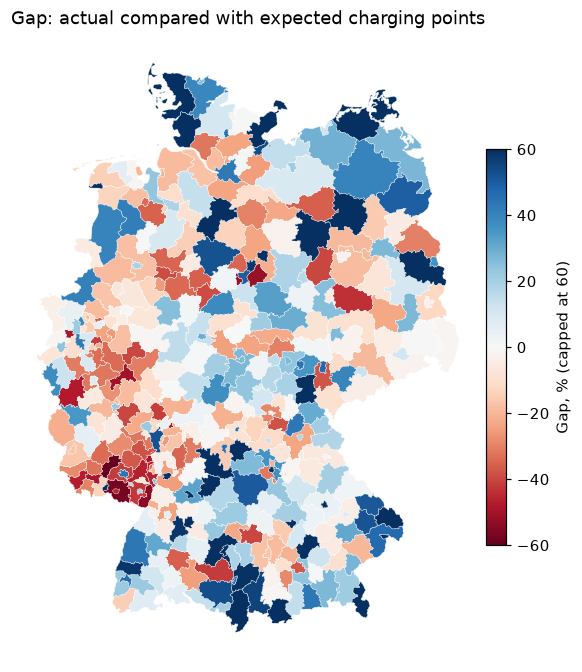

In [2]:
fig = plot_static_map(ranking, geojson, "gap_pct", "Gap: actual compared with expected charging points", "Gap, % (capped at 60)", GAP_LIMIT)
show(fig)

**What the map shows.** The districts below expected are not spread evenly. The deepest red is in the south-west (Rheinland-Pfalz and Saarland) and in parts of Nordrhein-Westfalen and Hessen. Many districts in the north and east and a number in Bayern and Baden-Württemberg are above expected. This is the state pattern from the model notebook: the model does not know the federal state.

## 3. Missing charging points in the clearly below districts

Only the 55 districts that are more than 30% below expected are coloured. The colour is the number of missing points (expected minus actual).

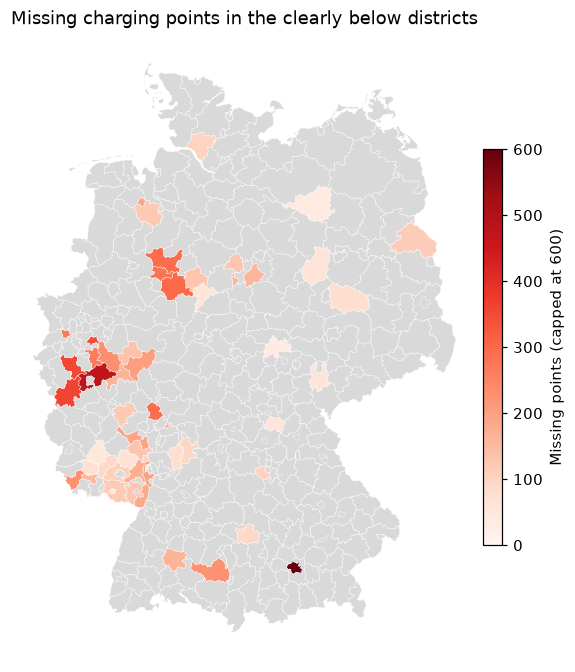

In [3]:
fig = plot_static_map(
    ranking.assign(missing=ranking["missing_to_expected"].clip(upper=POINTS_LIMIT)), geojson, "missing",
    "Missing charging points in the clearly below districts", "Missing points (capped at 600)", POINTS_LIMIT,
    cmap="Reds", centre=None, mask=ranking["clearly_below"])
show(fig)

**What the map shows.** In absolute numbers, München is the darkest spot by far (1,817 missing points, cut off at 600 in the colours). Around Köln the Rhein-Sieg-Kreis and the Euskirchen district stand out, followed by clusters in Rheinland-Pfalz and Nordrhein-Westfalen. Köln and Bonn themselves are not clearly below (Bonn is the grey patch inside the Rhein-Sieg-Kreis).

## 4. The interactive map

`reports/gap_map.html` is one file of about 6 MB that contains the plotly library, so it works without internet. A drop-down menu in the upper left switches between three views:

1. **Gap in percent** (as above)
2. **Missing charging points** (clearly below districts only)
3. **Clearly below: robust or not.** Robust means gradient boosting also puts the district more than 30% below expected.

Hovering over a district shows its name, state, actual and expected charging points, gap, missing points and both ranks.

## 5. The API

A small web service (FastAPI) with four endpoints:

| Endpoint | Returns |
|---|---|
| `GET /districts` | all districts, for a drop-down menu |
| `GET /districts/{key}` | actual and expected charging points, gap, missing points and ranks of one district |
| `GET /expected?bev=&population=&density=` | what-if: the expected charging points for these numbers |
| `GET /health` | status and the typical error of the model |

`GET /` serves a page with the map, a district drop-down and a what-if form. `GET /docs` shows the documentation of all endpoints. Start the service with `uv run uvicorn ev_gap.api:create_app --factory`.

The district endpoint returns the stored values, where the expected number comes from a model that did not see the district. The what-if endpoint uses the final model, trained on all 399 districts. Below, the service is called inside the notebook, without starting a server.

In [4]:
from fastapi.testclient import TestClient

from ev_gap.api import create_app

client = TestClient(create_app())
print(client.get("/health").json())
print()
kusel = client.get("/districts/07336").json()
print({key: kusel[key] for key in ["name", "state", "actual", "expected", "gap_pct", "missing_points", "clearly_below", "robust", "rank_by_percent", "rank_by_points"]})

{'status': 'ok', 'districts': 399, 'typical_error_pct': 21.1, 'data_dates': {'charging_register': '2026-11-12', 'kba_car_stock': '2026-01-01', 'destatis_population': '2024-12-31', 'pipeline_run_utc': '2026-11-25T23:16:45+00:00'}}

{'name': 'Kusel', 'state': 'Rheinland-Pfalz', 'actual': 60, 'expected': 150.2, 'gap_pct': -60.1, 'missing_points': 90.2, 'clearly_below': True, 'robust': True, 'rank_by_percent': 1, 'rank_by_points': 79}


c:\Users\flori\Desktop\NeueFische_gitrepos\ev-charging-gap-germany\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


In [5]:
# What-if: the same inputs as Kusel, then with twice the electric cars
for bev in (1262, 2524):
    result = client.get("/expected", params={"bev": bev, "population": 69334, "density": 121}).json()
    print(f"{bev} battery electric cars, 69,334 residents, 121 per km2 -> expected {result['expected_points']} charging points (typical error about {result['typical_error_pct']}%)")

# Invalid input is rejected with a clear message
bad = client.get("/expected", params={"bev": 0, "population": 69334, "density": 121})
print()
print(bad.status_code, bad.json()["detail"][0]["msg"])

1262 battery electric cars, 69,334 residents, 121 per km2 -> expected 150.0 charging points (typical error about 21.1%)
2524 battery electric cars, 69,334 residents, 121 per km2 -> expected 209.2 charging points (typical error about 21.1%)

422 Input should be greater than 0


**Notes**

- The expected number is not the number of charging points that a district needs. It is what a typical district with the same cars, residents and density has.
- The what-if endpoint accepts values within the range of the real districts (battery electric cars up to 200,000, residents between 1,000 and 5 million, density up to 20,000 per km2). The model has not seen values outside the range of the 399 districts and is least reliable at the edges.
- Doubling the electric cars does not double the expected charging points (the elasticity is about 0.5). This is the effect found in the data exploration.